# Week 8: Evaluation

============================================================

IDX Exchange — Data Science Internship

Week 8: Evaluation

Author: Zachary Blehm

============================================================

Overview:

Part 1:

The final dataset is re-evaluated using an expanded list of metrics across the different models considered up to this point. Additionally, since we know have a finalized dataset and optimized parameters, we use the train/test data rather than train/validate/test (with the test having been unused up to this point).

To repeat the explanation of the final dataset from the previous notebook, the data set is a combination of the week 3 and week 6 pipelines. Imputation is based on aggregates computed over the full warm-up + training set (6 + 18 = 24 months). The zip level and knn aggregate calculations are based on an expanding window, while the zip price trend uses a 6 month moving window.

The feature set is also a combination of the week 3 and week 6 features sets, and uses all of the original (week 3) features, plus the additional features created in week 6.

The choice of this data set is based on the best overall performance of any dataset previously evaluated.

We evaluate each model using previously found best parameters and then further explore the results by quartiles and by number of bedrooms and bathrooms.

Part 2:

Part 1 is repeated using the a subset of features. The feature subset is based on what will be useful for next weeks task of creating an app. Some features in the full feature set (e.g. FireplaceYN, YearBuilt etc.) would make the app to complicated for the average user and thus are dropped for this investigation. Note that this feature set corresponds to the same feature subset examined in part 2 of 05_Advanced_Models last week.





In [1]:
import pandas as pd
import numpy as np
import xgboost as xgb
import shap
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.model_selection import ParameterGrid
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Training data is 18 months total (used +6 months for aggregate warm-up)
# Test is 202604

df_train = pd.read_csv("train_final_v3_18mo_6mo_mw_large_feature_set.csv")
df_test = pd.read_csv("test_final_v3_18mo_6mo_mw_large_feature_set.csv")

# Part 1

In [3]:
# Columns to scale (numeric inputs only)
scale_cols = [
    "LivingArea",
    "LotSizeSquareFeet",
    "Latitude",
    "Longitude",
    "HOA_AnnualFee",
    "zip_median_price",
    "zip_median_ppsqft",
    "zip_median_living",
    "zip_price_trend",
    "knn_5_median_price",
    "knn_10_median_price",
    "knn_20_median_price",
    "knn_5_median_ppsqft",
    "knn_10_median_ppsqft",
    "knn_20_median_ppsqft",
    "knn_5_similar_median_price",
    "knn_10_similar_median_price",
    "knn_20_similar_median_price",
    "knn_5_similar_median_ppsqft",
    "knn_10_similar_median_ppsqft",
    "knn_20_similar_median_ppsqft",
    "knn_5_time_adjusted_price",
    "knn_10_time_adjusted_price",
    "knn_20_time_adjusted_price",
    "bed_bath_ratio"
]

In [4]:
# scaled data for linear regression
# Make copies
train_scaled = df_train.copy()
test_scaled = df_test.copy()

# Fit scaler on TRAIN ONLY
scaler = StandardScaler()
scaler.fit(train_scaled[scale_cols])

# Apply transform
train_scaled[scale_cols] = scaler.transform(train_scaled[scale_cols])
test_scaled[scale_cols] = scaler.transform(test_scaled[scale_cols])

In [5]:
def evaluate_regression_model(model, X_train, y_train,
                              X_test, y_test,
                              model_name="Model"):
    """
    Evaluate a fitted regression model on train and test data.
    Returns a DataFrame of metrics.
    """

    # Predictions
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    metrics = {
        "Dataset": ["Train", "Test"],

        "R-Squared": [
            r2_score(y_train, y_pred_train),
            r2_score(y_test, y_pred_test)
        ],

        "MAE": [
            mean_absolute_error(y_train, y_pred_train),
            mean_absolute_error(y_test, y_pred_test)
        ],

        "RMSE": [
            np.sqrt(mean_squared_error(y_train, y_pred_train)),
            np.sqrt(mean_squared_error(y_test, y_pred_test))
        ],

        "MAPE (%)": [
            np.mean(np.abs((y_train - y_pred_train) / y_train)) * 100,
            np.mean(np.abs((y_test - y_pred_test) / y_test)) * 100
        ],

        "MdAPE (%)": [
            np.median(np.abs((y_train - y_pred_train) / y_train)) * 100,
            np.median(np.abs((y_test - y_pred_test) / y_test)) * 100
        ]
    }

    results = pd.DataFrame(metrics)

    print(f"\n{model_name}")
    print(results)

    return results

In [43]:
def evaluate_by_price_band(
    model,
    X_test,
    y_test,
    n_bands=4,
    title="MdAPE by Price Band"
):
    """
    Evaluate regression performance by price bands.

    Returns
    -------
    summary : DataFrame
        Performance metrics by price band.

    """

    # Predictions
    y_pred = model.predict(X_test)

    results = pd.DataFrame({
        "ActualPrice": np.asarray(y_test),
        "PredictedPrice": np.asarray(y_pred)
    })

    # Remove invalid observations
    results = results.dropna()

    results = results[
        (results["ActualPrice"] > 0) &
        np.isfinite(results["ActualPrice"]) &
        np.isfinite(results["PredictedPrice"])
    ].copy()

    # Create quantile bands
    results["Band"] = pd.qcut(
        results["ActualPrice"],
        q=n_bands,
        labels=[f"Band {i+1}" for i in range(n_bands)]
    )

    rows = []

    for band, group in results.groupby("Band", observed=True):

        abs_error = np.abs(
            group["ActualPrice"] - group["PredictedPrice"]
        )

        abs_pct_error = (
            abs_error / group["ActualPrice"]
        )

        rows.append({
            "Band": band,
            "Min Price": group["ActualPrice"].min(),
            "Max Price": group["ActualPrice"].max(),
            "Count": len(group),
            "MAE": abs_error.mean(),
            "MAPE (%)": abs_pct_error.mean() * 100,
            "MdAPE (%)": np.median(abs_pct_error) * 100,
            "% Within 5%": (abs_pct_error <= 0.05).mean() * 100,
            "% Within 10%": (abs_pct_error <= 0.10).mean() * 100
        })

    summary = pd.DataFrame(rows)

    # Plot MdAPE by Price Band

    plt.figure(figsize=(8, 4))

    ax = sns.barplot(
        data=summary,
        x="Band",
        y="MdAPE (%)",
        hue="Band",
        palette="Blues",
        legend=False
    )

    # Add observation counts above bars
    for i, row in summary.reset_index(drop=True).iterrows():

        ax.text(
            i,
            row["MdAPE (%)"],
            f'{row["MdAPE (%)"]:.1f}%\n(n={row["Count"]})',
            ha="center",
            va="bottom",
            fontsize=10
        )

    plt.title(title, fontsize=14)
    plt.xlabel("Price Band")
    plt.ylabel("Median Absolute Percentage Error (%)")

    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    return summary


In [7]:
def plot_mdape_bed_bath_matrix(
    model,
    X_test,
    y_test,
    bedrooms_col="BedroomsTotal",
    bathrooms_col="BathroomsTotalInteger",
    title="MdAPE by Bedroom/Bathroom Combination"
):
    """
    Plot a bedroom x bathroom matrix where:

    - Cell color = number of observations
    - Cell annotation = MdAPE (%)

    Parameters
    ----------
    model : fitted regression model
    X_test : feature dataframe
    y_test : actual target values
    bedrooms_col : bedroom column name
    bathrooms_col : bathroom column name
    title : chart title

    Returns
    -------
    mdape_matrix : DataFrame
    count_matrix : DataFrame
    """

    # Predictions
    y_pred = model.predict(X_test)

    # Create analysis dataframe
    results = pd.DataFrame({
        "Bedrooms": X_test[bedrooms_col],
        "Bathrooms": X_test[bathrooms_col],
        "ActualPrice": y_test,
        "PredictedPrice": y_pred
    })

    # Absolute percentage error
    results["APE"] = (
        np.abs(
            results["ActualPrice"] -
            results["PredictedPrice"]
        ) / results["ActualPrice"]
    ) * 100

    # MdAPE matrix
    mdape_matrix = pd.pivot_table(
        results,
        values="APE",
        index="Bedrooms",
        columns="Bathrooms",
        aggfunc="median"
    )

    # Count matrix
    count_matrix = pd.pivot_table(
        results,
        values="APE",
        index="Bedrooms",
        columns="Bathrooms",
        aggfunc="count"
    )

    # Build annotation strings
    annotations = mdape_matrix.round(1).astype(str)

    # Replace missing values with blank
    annotations = annotations.replace("nan", "")

    plt.figure(figsize=(12, 8))

    sns.heatmap(
        count_matrix,
        annot=annotations,
        fmt="",
        cmap="Blues",
        linewidths=0.5,
        cbar_kws={"label": "Number of Listings"}
    )

    plt.title(
        f"{title}\n(Cell Value = MdAPE %, Color = Listing Count)",
        fontsize=14
    )

    plt.xlabel("Bathrooms")
    plt.ylabel("Bedrooms")

    plt.tight_layout()
    plt.show()

    return mdape_matrix, count_matrix

In [8]:
y_train = df_train["ClosePrice"].copy()
X_train = df_train.drop(columns=["ClosePrice"]).copy()

y_test = df_test["ClosePrice"].copy()
X_test = df_test.drop(columns=["ClosePrice"]).copy()

y_train_scaled = train_scaled["ClosePrice"].copy()
X_train_scaled = train_scaled.drop(columns=["ClosePrice"]).copy()

y_test_scaled = test_scaled["ClosePrice"].copy()
X_test_scaled = test_scaled.drop(columns=["ClosePrice"]).copy()

In [9]:
lr_model = LinearRegression()

lr_model.fit(X_train_scaled, y_train)

results_lr = evaluate_regression_model(
    lr_model,
    X_train_scaled,
    y_train,
    X_test_scaled,
    y_test,
    model_name="Linear Regression"
)


Linear Regression
  Dataset  R-Squared            MAE           RMSE   MAPE (%)  MdAPE (%)
0   Train   0.889412  159338.601868  289117.207298  13.873544  10.111282
1    Test   0.898674  162632.507635  291787.000591  13.681874  10.035087


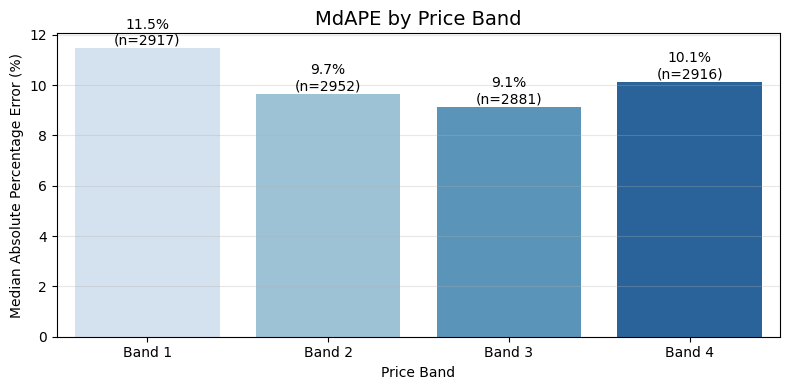

,Band,Min Price,Max Price,Count,MAE,MAPE (%),MdAPE (%),% Within 5%,% Within 10%
0,Band 1,195000.0,629990.0,2917,73052.431628,16.585597,11.485040,24.237230,45.149126
1,Band 2,630000.0,910000.0,2952,97696.105275,12.768141,9.659836,28.252033,51.558266
2,Band 3,911000.0,1470000.0,2881,142143.330945,12.288564,9.146529,28.670600,53.523082
3,Band 4,1471000.0,7175000.0,2916,338224.640532,13.078755,10.138890,25.994513,49.279835


In [44]:
price_band_results_lr = evaluate_by_price_band(
    lr_model,
    X_test_scaled,
    y_test,
    n_bands=4
)

price_band_results_lr

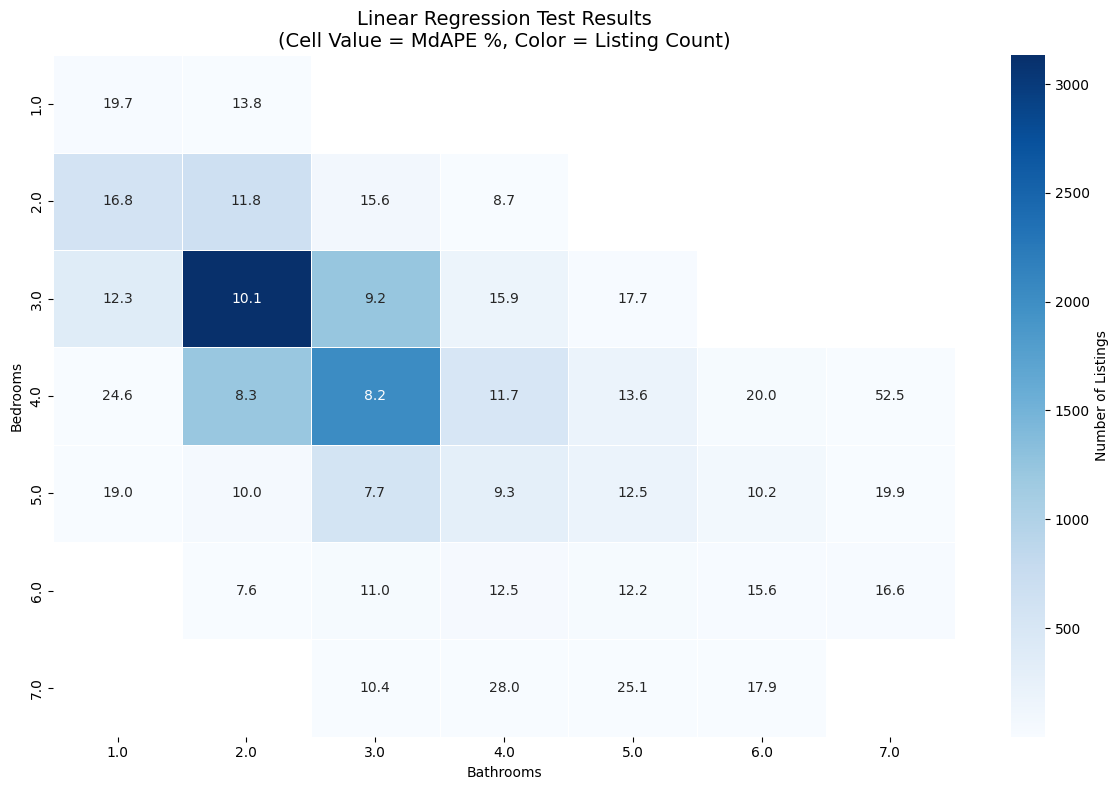

(Bathrooms        1.0        2.0        3.0        4.0        5.0        6.0  \
 Bedrooms                                                                      
 1.0        19.734451  13.782088        NaN        NaN        NaN        NaN   
 2.0        16.810628  11.772685  15.643374   8.669503        NaN        NaN   
 3.0        12.290849  10.105981   9.220876  15.870939  17.725032        NaN   
 4.0        24.602405   8.269241   8.171813  11.709706  13.609236  20.030588   
 5.0        19.024482  10.007430   7.678180   9.305483  12.540300  10.191907   
 6.0              NaN   7.644785  11.031234  12.533884  12.152159  15.616996   
 7.0              NaN        NaN  10.403566  28.030822  25.114142  17.888192   
 
 Bathrooms        7.0  
 Bedrooms              
 1.0              NaN  
 2.0              NaN  
 3.0              NaN  
 4.0        52.500091  
 5.0        19.855453  
 6.0        16.617583  
 7.0              NaN  ,
 Bathrooms    1.0     2.0     3.0    4.0    5.0   6.0   7.0
 

In [11]:
plot_mdape_bed_bath_matrix(
    lr_model,
    X_test_scaled,
    y_test,
    title="Linear Regression Test Results"
)

In [12]:
dt_model = DecisionTreeRegressor(
    random_state=42,
    max_depth=10,
    min_samples_leaf=10
)

dt_model.fit(X_train, y_train)

results_dt = evaluate_regression_model(
    dt_model,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="Decision Tree"
)


Decision Tree
  Dataset  R-Squared            MAE           RMSE   MAPE (%)  MdAPE (%)
0   Train   0.902937  147821.106279  270860.175193  12.145574   8.371615
1    Test   0.885828  162442.376996  309731.536038  12.518971   8.387518


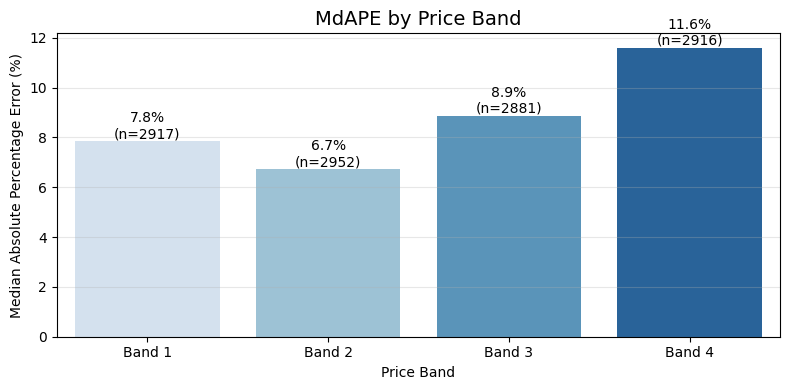

,Band,Min Price,Max Price,Count,MAE,MAPE (%),MdAPE (%),% Within 5%,% Within 10%
0,Band 1,195000.0,629990.0,2917,58204.486250,13.563581,7.834715,34.590333,58.484745
1,Band 2,630000.0,910000.0,2952,75332.037037,9.815608,6.715578,39.735772,67.479675
2,Band 3,911000.0,1470000.0,2881,138459.490246,11.899161,8.869341,29.677195,54.807359
3,Band 4,1471000.0,7175000.0,2916,378596.817186,14.823112,11.595828,22.839506,43.758573


In [13]:
price_band_results_dt = evaluate_by_price_band(
    dt_model,
    X_test,
    y_test,
    n_bands=4
)

price_band_results_dt

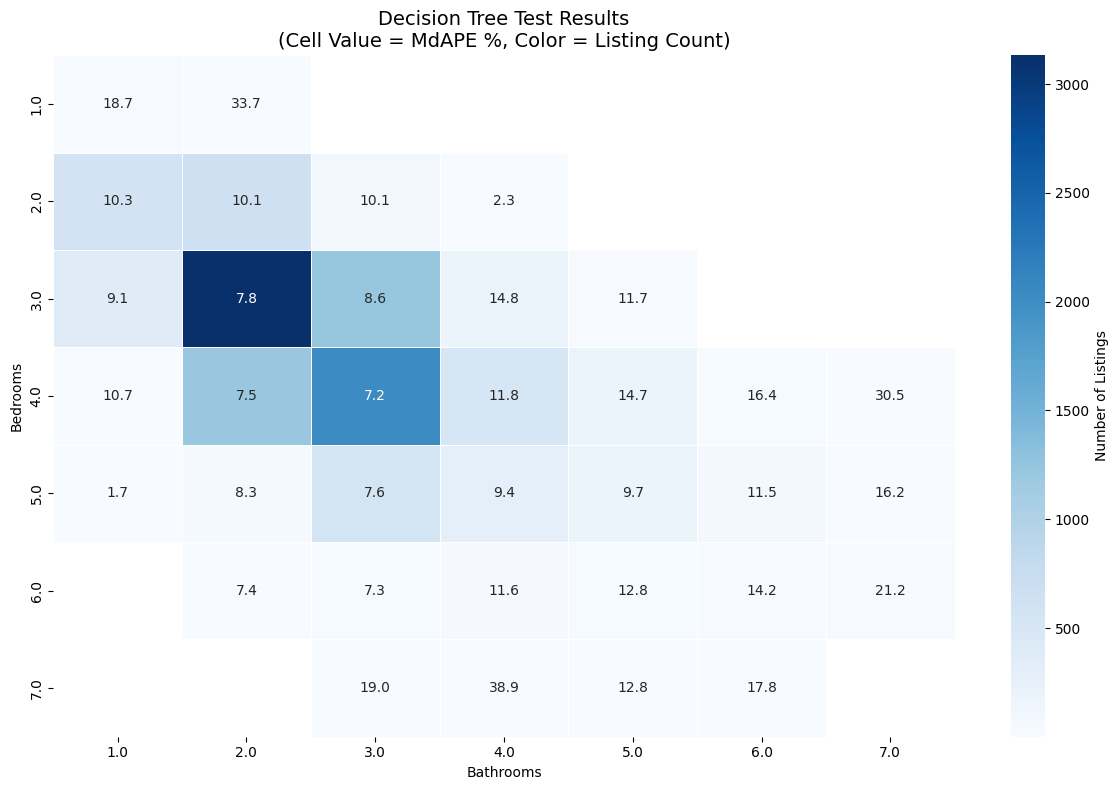

(Bathrooms        1.0        2.0        3.0        4.0        5.0        6.0  \
 Bedrooms                                                                      
 1.0        18.679894  33.679275        NaN        NaN        NaN        NaN   
 2.0        10.342456  10.098473  10.057558   2.331139        NaN        NaN   
 3.0         9.107265   7.816367   8.595760  14.808826  11.743107        NaN   
 4.0        10.729618   7.486966   7.161629  11.805752  14.722520  16.404098   
 5.0         1.673177   8.314791   7.607679   9.435507   9.691166  11.457742   
 6.0              NaN   7.413501   7.264378  11.608011  12.823122  14.212963   
 7.0              NaN        NaN  19.001105  38.896255  12.765573  17.779493   
 
 Bathrooms        7.0  
 Bedrooms              
 1.0              NaN  
 2.0              NaN  
 3.0              NaN  
 4.0        30.538505  
 5.0        16.196566  
 6.0        21.238911  
 7.0              NaN  ,
 Bathrooms    1.0     2.0     3.0    4.0    5.0   6.0   7.0
 

In [14]:
plot_mdape_bed_bath_matrix(
    dt_model,
    X_test,
    y_test,
    title="Decision Tree Test Results"
)

In [15]:
rf_model = RandomForestRegressor(
    max_depth=10,
    n_estimators=15,
    min_samples_leaf=2,
    random_state=42
)

rf_model.fit(X_train, y_train)

results_rf = evaluate_regression_model(
    rf_model,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="Random Forest"
)


Random Forest
  Dataset  R-Squared            MAE           RMSE   MAPE (%)  MdAPE (%)
0   Train   0.919458  137980.754509  246734.943395  11.541809   7.890017
1    Test   0.899206  153590.740246  291021.035456  11.946948   7.943485


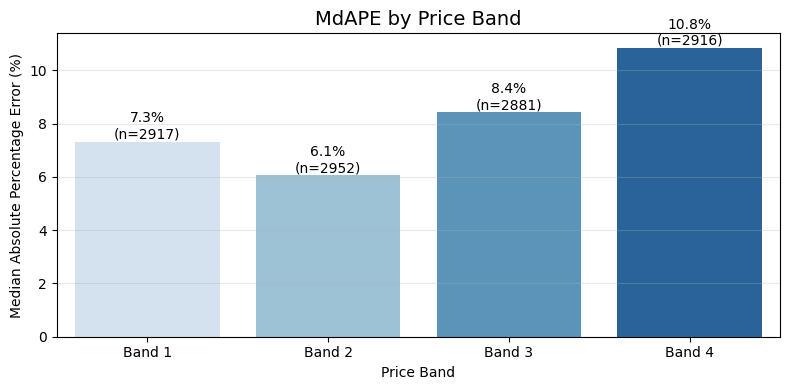

,Band,Min Price,Max Price,Count,MAE,MAPE (%),MdAPE (%),% Within 5%,% Within 10%
0,Band 1,195000.0,629990.0,2917,56800.094552,13.248978,7.325013,36.818649,60.473089
1,Band 2,630000.0,910000.0,2952,72120.339529,9.396059,6.066271,42.479675,69.512195
2,Band 3,911000.0,1470000.0,2881,133069.911884,11.411381,8.418044,30.579660,57.132940
3,Band 4,1471000.0,7175000.0,2916,353165.309147,13.755991,10.846705,25.274348,46.810700


In [16]:
price_band_results_rf = evaluate_by_price_band(
    rf_model,
    X_test,
    y_test,
    n_bands=4
)

price_band_results_rf

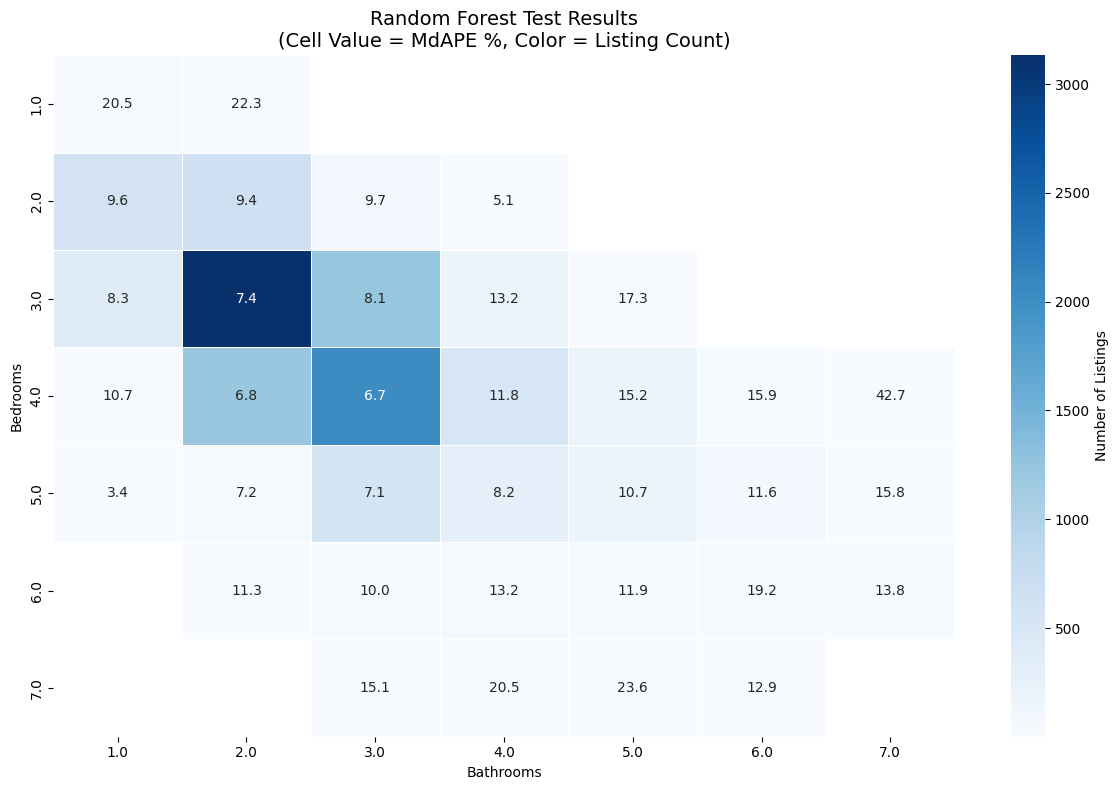

(Bathrooms        1.0        2.0        3.0        4.0        5.0        6.0  \
 Bedrooms                                                                      
 1.0        20.456920  22.306081        NaN        NaN        NaN        NaN   
 2.0         9.614159   9.369920   9.738611   5.100941        NaN        NaN   
 3.0         8.290957   7.361492   8.095621  13.220681  17.263021        NaN   
 4.0        10.650781   6.823116   6.745006  11.843082  15.234937  15.940063   
 5.0         3.393136   7.192366   7.094946   8.226630  10.672552  11.624495   
 6.0              NaN  11.272616   9.977796  13.215393  11.892848  19.184052   
 7.0              NaN        NaN  15.053435  20.519557  23.605574  12.876206   
 
 Bathrooms        7.0  
 Bedrooms              
 1.0              NaN  
 2.0              NaN  
 3.0              NaN  
 4.0        42.743617  
 5.0        15.848283  
 6.0        13.754082  
 7.0              NaN  ,
 Bathrooms    1.0     2.0     3.0    4.0    5.0   6.0   7.0
 

In [17]:
plot_mdape_bed_bath_matrix(
    rf_model,
    X_test,
    y_test,
    title="Random Forest Test Results"
)

In [18]:
xgb_model = XGBRegressor(
    random_state=42,
    objective="reg:squarederror",
    learning_rate = 0.015,
    max_depth = 4,
    n_estimators = 3000
)

xgb_model.fit(X_train, y_train)

# Results
results_xgb = evaluate_regression_model(
    xgb_model,
    X_train,
    y_train,
    X_test,
    y_test,
    model_name="XGBoost"
)


XGBoost
  Dataset  R-Squared            MAE           RMSE   MAPE (%)  MdAPE (%)
0   Train   0.931611  125325.474201  227359.452642  10.512605   7.259912
1    Test   0.918825  138978.840850  261165.734887  10.994475   7.596221


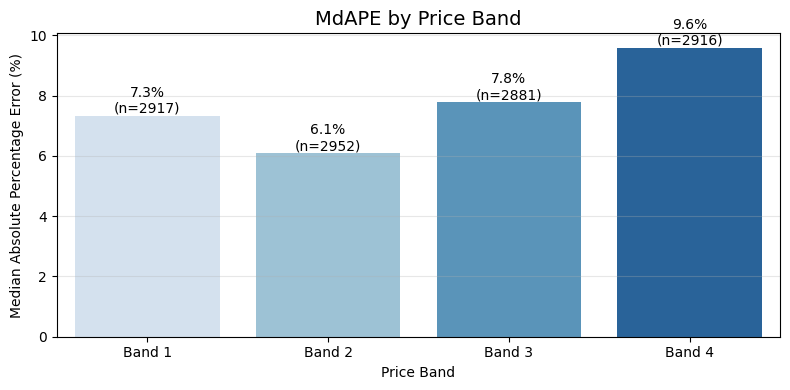

,Band,Min Price,Max Price,Count,MAE,MAPE (%),MdAPE (%),% Within 5%,% Within 10%
0,Band 1,195000.0,629990.0,2917,53433.503005,12.327411,7.327081,37.538567,61.878642
1,Band 2,630000.0,910000.0,2952,67994.597127,8.856511,6.081966,42.208672,70.494580
2,Band 3,911000.0,1470000.0,2881,122847.884978,10.516145,7.785753,33.252343,60.499826
3,Band 4,1471000.0,7175000.0,2916,312351.447787,12.298031,9.590647,27.846365,51.474623


In [19]:
price_band_results_xgb = evaluate_by_price_band(
    xgb_model,
    X_test,
    y_test,
    n_bands=4
)

price_band_results_xgb

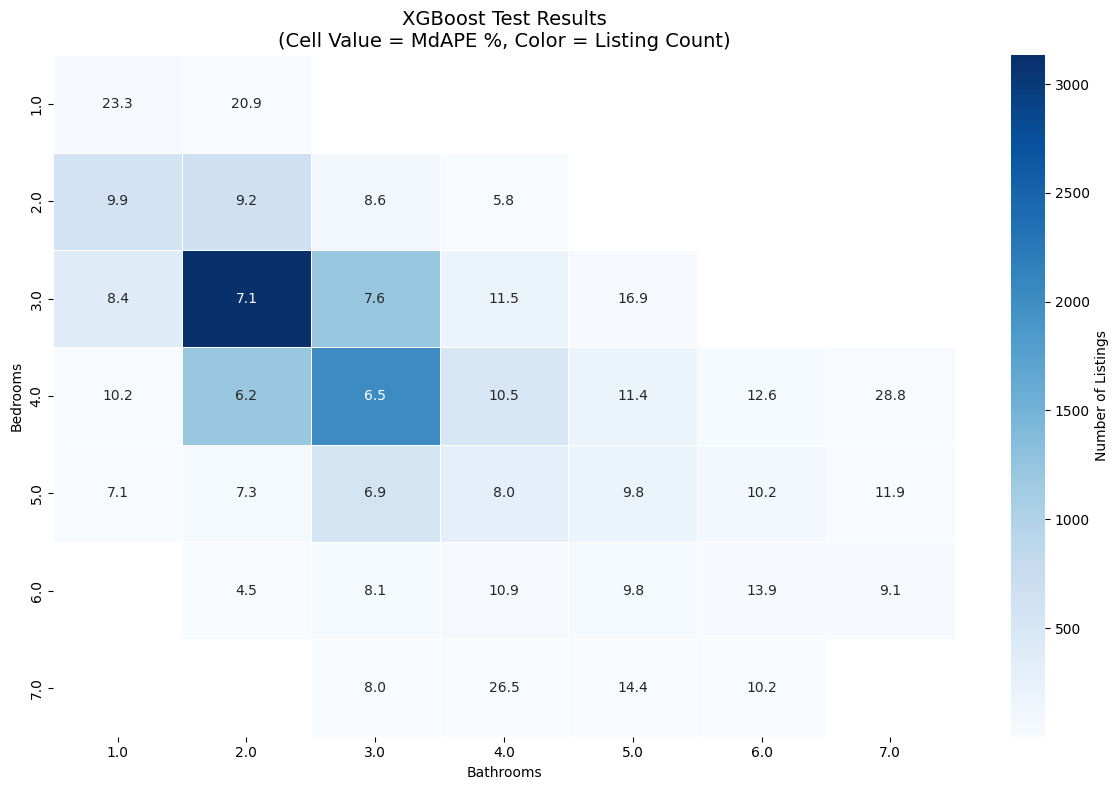

(Bathrooms        1.0        2.0       3.0        4.0        5.0        6.0  \
 Bedrooms                                                                     
 1.0        23.250708  20.920303       NaN        NaN        NaN        NaN   
 2.0         9.898726   9.189251  8.588811   5.789122        NaN        NaN   
 3.0         8.426327   7.096180  7.645852  11.451723  16.892191        NaN   
 4.0        10.231278   6.239081  6.455386  10.507233  11.380290  12.649884   
 5.0         7.104519   7.347031  6.862566   8.038024   9.802251  10.162200   
 6.0              NaN   4.532542  8.061121  10.893353   9.819036  13.890432   
 7.0              NaN        NaN  8.009358  26.485444  14.448843  10.249855   
 
 Bathrooms        7.0  
 Bedrooms              
 1.0              NaN  
 2.0              NaN  
 3.0              NaN  
 4.0        28.754436  
 5.0        11.878795  
 6.0         9.052711  
 7.0              NaN  ,
 Bathrooms    1.0     2.0     3.0    4.0    5.0   6.0   7.0
 Bedrooms 

In [20]:
plot_mdape_bed_bath_matrix(
    xgb_model,
    X_test,
    y_test,
    title="XGBoost Test Results"
)

In [21]:
all_results = pd.concat([
    results_lr.assign(Model="Linear Regression"),
    results_dt.assign(Model="Decision Tree"),
    results_rf.assign(Model="Random Forest"),
    results_xgb.assign(Model="XGBoost")
])

display(all_results)

,Dataset,R-Squared,MAE,RMSE,MAPE (%),MdAPE (%),Model
0,Train,0.889412,159338.601868,289117.207298,13.873544,10.111282,Linear Regression
1,Test,0.898674,162632.507635,291787.000591,13.681874,10.035087,Linear Regression
0,Train,0.902937,147821.106279,270860.175193,12.145574,8.371615,Decision Tree
1,Test,0.885828,162442.376996,309731.536038,12.518971,8.387518,Decision Tree
0,Train,0.919458,137980.754509,246734.943395,11.541809,7.890017,Random Forest
1,Test,0.899206,153590.740246,291021.035456,11.946948,7.943485,Random Forest
0,Train,0.931611,125325.474201,227359.452642,10.512605,7.259912,XGBoost
1,Test,0.918825,138978.840850,261165.734887,10.994475,7.596221,XGBoost


## Part 1 Summary

Overall the final XGBoost model performs best over all metrics on the test data as a whole.

At the price band (quartiles) level, XGBoost is also the best model in terms of MdAPE performance, although Random Forest is able to match within the lowest two quartiles. Additionally XGBoost had the high percent of predicted test values within 5% of the actual values for quartiles 1, 3, and 4 and was only outperformed for quartile 2 by Random Forest by 0.28%.

# Part 2

In [22]:
app_features = [
    "ClosePrice", # target
    "BedroomsTotal",
    "BathroomsTotalInteger",
    "bed_bath_ratio",
    "LivingArea",
    "LotSizeSquareFeet",
    "FireplaceYN",
    "knn_5_similar_median_price",
    "knn_10_similar_median_price",
    "knn_20_similar_median_price",
    "knn_5_median_price",
    "knn_10_median_price",
    "knn_20_median_price",
    "knn_5_time_adjusted_price",
    "knn_10_time_adjusted_price",
    "knn_20_time_adjusted_price",
    "knn_5_similar_median_ppsqft",
    "knn_10_similar_median_ppsqft",
    "knn_20_similar_median_ppsqft",
    "knn_5_median_ppsqft",
    "knn_10_median_ppsqft",
    "knn_20_median_ppsqft",
    "zip_median_price",
    "zip_median_ppsqft"
]

scale_cols = app_features.copy()
scale_cols.remove("ClosePrice")

In [23]:
# Data sets for just the subset of features
df_train_app = df_train[app_features].copy()
df_test_app = df_test[app_features].copy()

In [24]:
# scaled data for linear regression
# Make copiestrain_scaled_6mo_12mo = df_train_6mo_12mo.copy()
train_scaled_app = df_train_app.copy()
test_scaled_app = df_test_app.copy()


# Fit scaler on TRAIN ONLY
scaler = StandardScaler()
scaler.fit(train_scaled_app[scale_cols])

# Apply transform
train_scaled_app[scale_cols] = scaler.transform(train_scaled_app[scale_cols])
test_scaled_app[scale_cols] = scaler.transform(test_scaled_app[scale_cols])

In [25]:
y_train_app = df_train_app["ClosePrice"].copy()
X_train_app = df_train_app.drop(columns=["ClosePrice"]).copy()

y_test_app = df_test_app["ClosePrice"].copy()
X_test_app = df_test_app.drop(columns=["ClosePrice"]).copy()

X_train_scaled_app = train_scaled_app.drop(columns=["ClosePrice"]).copy()

X_test_scaled_app = test_scaled_app.drop(columns=["ClosePrice"]).copy()

In [26]:
lr_model_app = LinearRegression()

lr_model_app.fit(X_train_scaled_app, y_train_app)

results_lr_app = evaluate_regression_model(
    lr_model_app,
    X_train_scaled_app,
    y_train_app,
    X_test_scaled_app,
    y_test_app,
    model_name="Linear Regression"
)


Linear Regression
  Dataset  R-Squared            MAE           RMSE   MAPE (%)  MdAPE (%)
0   Train   0.886408  161068.518183  293016.849701  13.851312  10.134863
1    Test   0.896615  163610.151020  294737.081159  13.586926  10.075945


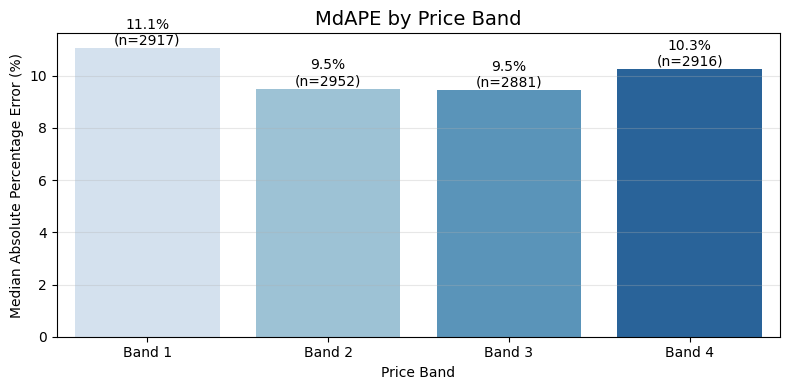

,Band,Min Price,Max Price,Count,MAE,MAPE (%),MdAPE (%),% Within 5%,% Within 10%
0,Band 1,195000.0,629990.0,2917,69932.632719,15.849016,11.072998,24.477203,45.560507
1,Band 2,630000.0,910000.0,2952,97761.880291,12.757204,9.510466,28.861789,52.235772
2,Band 3,911000.0,1470000.0,2881,144939.932081,12.517997,9.462191,28.531760,52.204096
3,Band 4,1471000.0,7175000.0,2916,342427.132103,13.220126,10.264226,26.817558,48.662551


In [27]:
price_band_results_lr_app = evaluate_by_price_band(
    lr_model_app,
    X_test_scaled_app,
    y_test_app,
    n_bands=4
)

price_band_results_lr_app

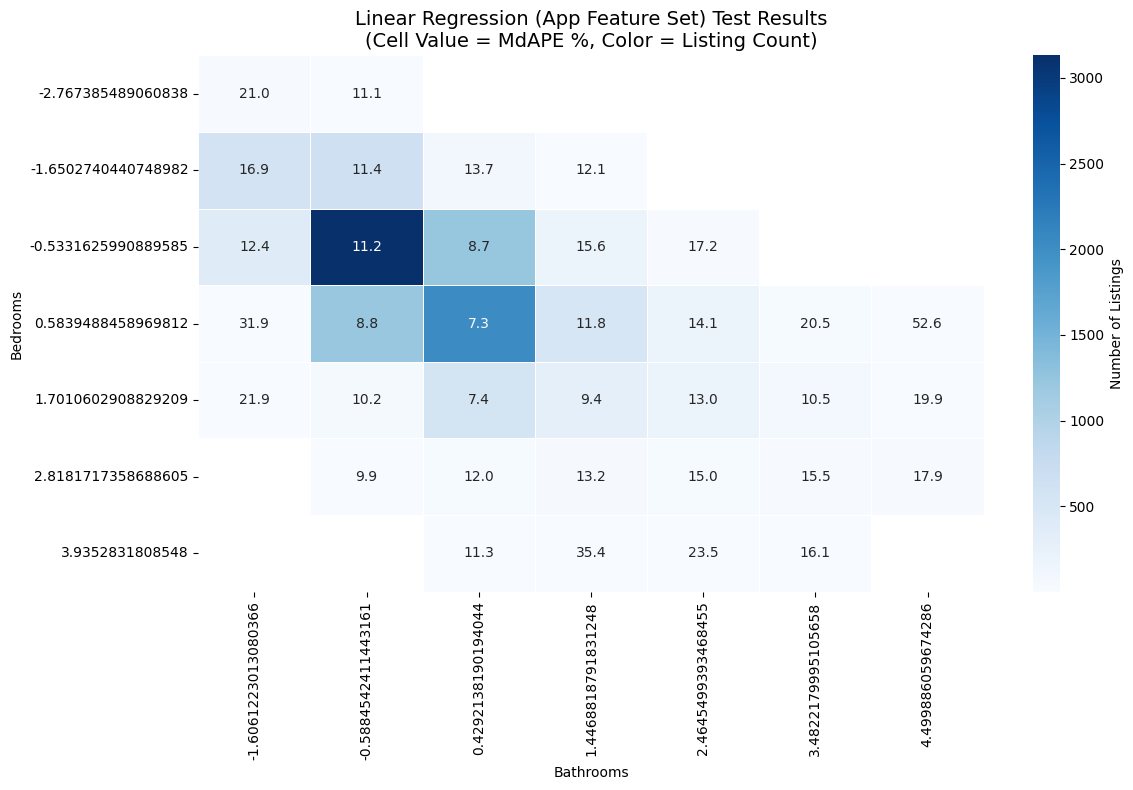

(Bathrooms  -1.606122  -0.588454   0.429214   1.446882   2.464550   3.482218  \
 Bedrooms                                                                      
 -2.767385  21.029452  11.141825        NaN        NaN        NaN        NaN   
 -1.650274  16.937814  11.406283  13.698424  12.098849        NaN        NaN   
 -0.533163  12.422262  11.193040   8.704855  15.577167  17.242932        NaN   
  0.583949  31.890464   8.777207   7.313625  11.821399  14.108909  20.541375   
  1.701060  21.906645  10.181296   7.363473   9.393741  13.012709  10.483583   
  2.818172        NaN   9.947584  12.019338  13.150205  14.967550  15.486701   
  3.935283        NaN        NaN  11.316807  35.435126  23.503856  16.139433   
 
 Bathrooms   4.499886  
 Bedrooms              
 -2.767385        NaN  
 -1.650274        NaN  
 -0.533163        NaN  
  0.583949  52.639404  
  1.701060  19.927215  
  2.818172  17.903651  
  3.935283        NaN  ,
 Bathrooms  -1.606122  -0.588454   0.429214   1.446882   2.46

In [28]:
plot_mdape_bed_bath_matrix(
    lr_model_app,
    X_test_scaled_app,
    y_test_app,
    title="Linear Regression (App Feature Set) Test Results"
)

In [29]:
dt_model_app = DecisionTreeRegressor(
    random_state=42,
    max_depth=10,
    min_samples_leaf=10
)

dt_model_app.fit(X_train_app, y_train_app)

results_dt_app = evaluate_regression_model(
    dt_model_app,
    X_train_app,
    y_train_app,
    X_test_app,
    y_test_app,
    model_name="Decision Tree"
)


Decision Tree
  Dataset  R-Squared            MAE           RMSE   MAPE (%)  MdAPE (%)
0   Train   0.901259  148272.113003  273191.640390  12.153048   8.339637
1    Test   0.885540  162656.097872  310122.849463  12.487682   8.409593


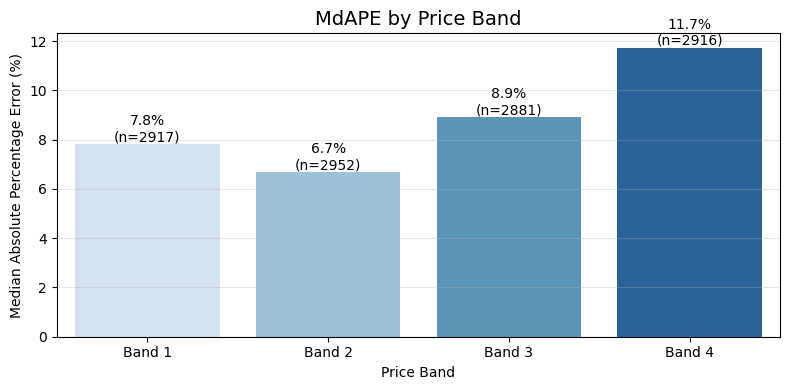

,Band,Min Price,Max Price,Count,MAE,MAPE (%),MdAPE (%),% Within 5%,% Within 10%
0,Band 1,195000.0,629990.0,2917,57919.754762,13.481222,7.812369,34.453205,58.450463
1,Band 2,630000.0,910000.0,2952,74535.617940,9.718661,6.669888,39.803523,67.615176
2,Band 3,911000.0,1470000.0,2881,138106.135409,11.874905,8.903827,29.434224,54.494967
3,Band 4,1471000.0,7175000.0,2916,380892.041448,14.902431,11.726406,22.702332,43.518519


In [30]:
price_band_results_dt_app = evaluate_by_price_band(
    dt_model_app,
    X_test_app,
    y_test_app,
    n_bands=4
)

price_band_results_dt_app

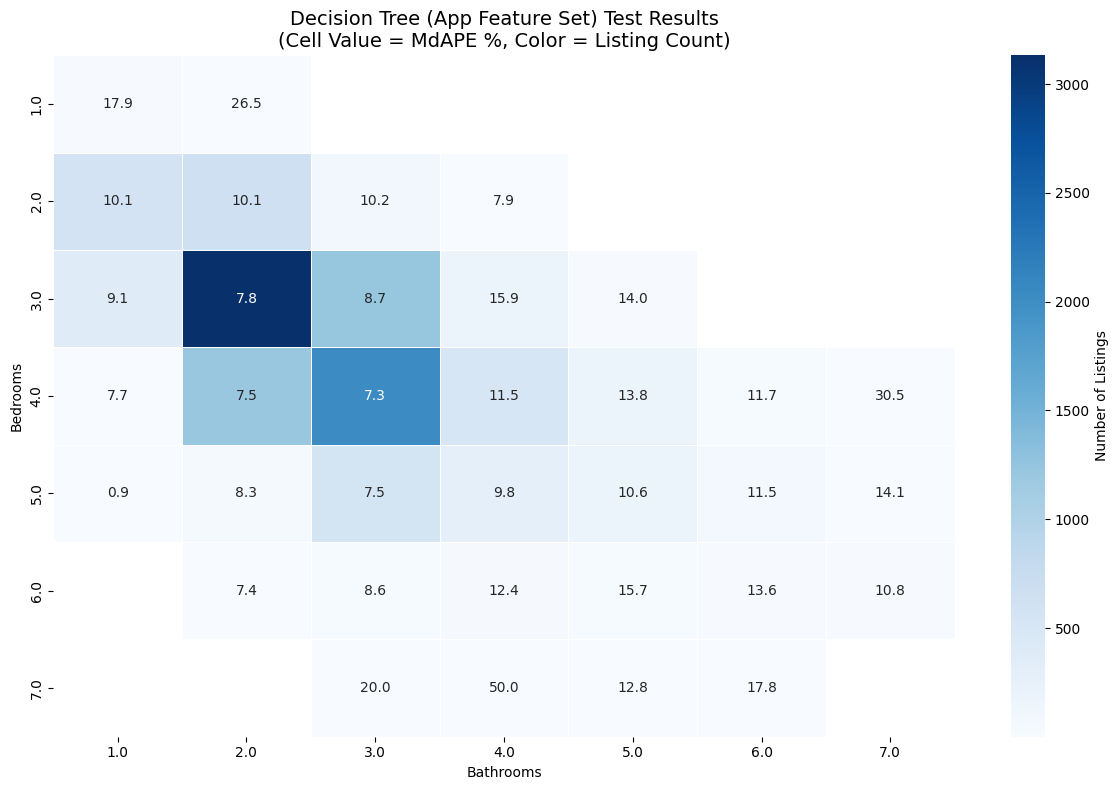

(Bathrooms        1.0        2.0        3.0        4.0        5.0        6.0  \
 Bedrooms                                                                      
 1.0        17.930303  26.534971        NaN        NaN        NaN        NaN   
 2.0        10.086488  10.098473  10.167162   7.906099        NaN        NaN   
 3.0         9.103196   7.847875   8.733359  15.896929  13.987328        NaN   
 4.0         7.664818   7.534040   7.296917  11.453315  13.828096  11.691870   
 5.0         0.857244   8.314791   7.545120   9.831541  10.570357  11.516485   
 6.0              NaN   7.413501   8.637189  12.386378  15.749574  13.633253   
 7.0              NaN        NaN  20.049143  50.038686  12.765573  17.779493   
 
 Bathrooms        7.0  
 Bedrooms              
 1.0              NaN  
 2.0              NaN  
 3.0              NaN  
 4.0        30.538505  
 5.0        14.134556  
 6.0        10.803767  
 7.0              NaN  ,
 Bathrooms    1.0     2.0     3.0    4.0    5.0   6.0   7.0
 

In [31]:
plot_mdape_bed_bath_matrix(
    dt_model_app,
    X_test_app,
    y_test_app,
    title="Decision Tree (App Feature Set) Test Results"
)

In [32]:
rf_model_app = RandomForestRegressor(
    max_depth=11,
    n_estimators=20,
    min_samples_leaf = 2,
    random_state=42
)

rf_model_app.fit(X_train_app, y_train_app)

results_rf_app = evaluate_regression_model(
    rf_model_app,
    X_train_app,
    y_train_app,
    X_test_app,
    y_test_app,
    model_name="Random Forest"
)


Random Forest
  Dataset  R-Squared            MAE           RMSE   MAPE (%)  MdAPE (%)
0   Train   0.927452  132370.588916  234170.925187  11.136882   7.689639
1    Test   0.901991  151843.249812  286971.761374  11.800930   7.880279


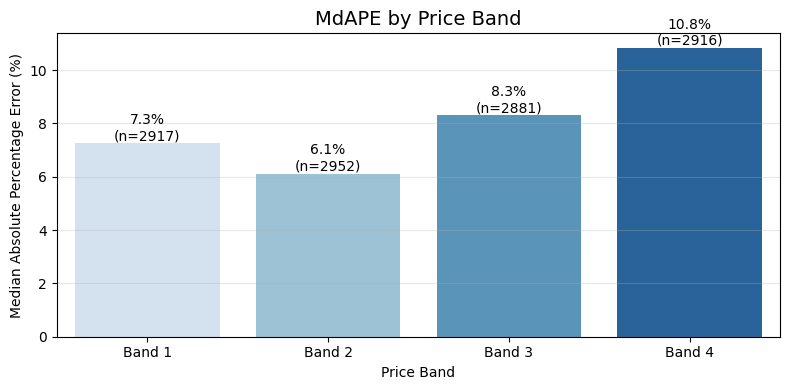

,Band,Min Price,Max Price,Count,MAE,MAPE (%),MdAPE (%),% Within 5%,% Within 10%
0,Band 1,195000.0,629990.0,2917,56360.828225,13.096618,7.256268,37.092904,61.021598
1,Band 2,630000.0,910000.0,2952,70808.795839,9.226429,6.114549,42.411924,69.579946
2,Band 3,911000.0,1470000.0,2881,131622.806583,11.277780,8.306761,30.857341,57.549462
3,Band 4,1471000.0,7175000.0,2916,349371.037481,13.627955,10.833867,24.931413,47.016461


In [34]:
price_band_results_rf_app = evaluate_by_price_band(
    rf_model_app,
    X_test_app,
    y_test_app,
    n_bands=4
)

price_band_results_rf_app

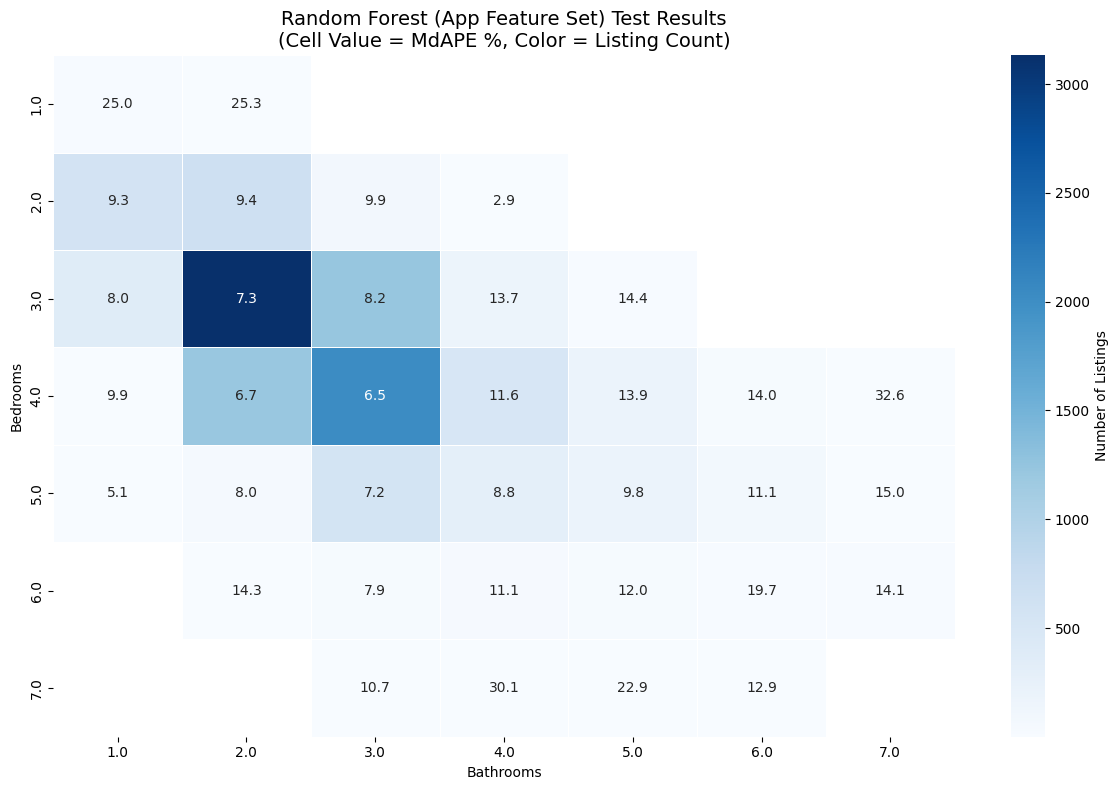

(Bathrooms        1.0        2.0        3.0        4.0        5.0        6.0  \
 Bedrooms                                                                      
 1.0        24.972211  25.269044        NaN        NaN        NaN        NaN   
 2.0         9.268711   9.400057   9.854152   2.926295        NaN        NaN   
 3.0         8.034502   7.323330   8.196652  13.692791  14.414484        NaN   
 4.0         9.883495   6.651484   6.509728  11.604707  13.917482  13.972773   
 5.0         5.061701   7.998194   7.176978   8.761923   9.750476  11.087315   
 6.0              NaN  14.262012   7.867027  11.128977  12.049764  19.657330   
 7.0              NaN        NaN  10.681487  30.144497  22.936218  12.923717   
 
 Bathrooms        7.0  
 Bedrooms              
 1.0              NaN  
 2.0              NaN  
 3.0              NaN  
 4.0        32.643338  
 5.0        15.046426  
 6.0        14.100936  
 7.0              NaN  ,
 Bathrooms    1.0     2.0     3.0    4.0    5.0   6.0   7.0
 

In [35]:
plot_mdape_bed_bath_matrix(
    rf_model_app,
    X_test_app,
    y_test_app,
    title="Random Forest (App Feature Set) Test Results"
)

In [36]:
xgb_model_app = XGBRegressor(
    random_state=42,
    objective="reg:squarederror",
    learning_rate = 0.001,
    max_depth = 4,
    n_estimators = 3000
)

xgb_model_app.fit(X_train_app, y_train_app)

# Results
results_xgb_app = evaluate_regression_model(
    xgb_model_app,
    X_train_app,
    y_train_app,
    X_test_app,
    y_test_app,
    model_name="XGBoost"
)


XGBoost
  Dataset  R-Squared            MAE           RMSE   MAPE (%)  MdAPE (%)
0   Train   0.887099  154485.940125  292124.293445  13.520470   9.042467
1    Test   0.894401  158744.078106  297875.818425  13.224548   8.810279


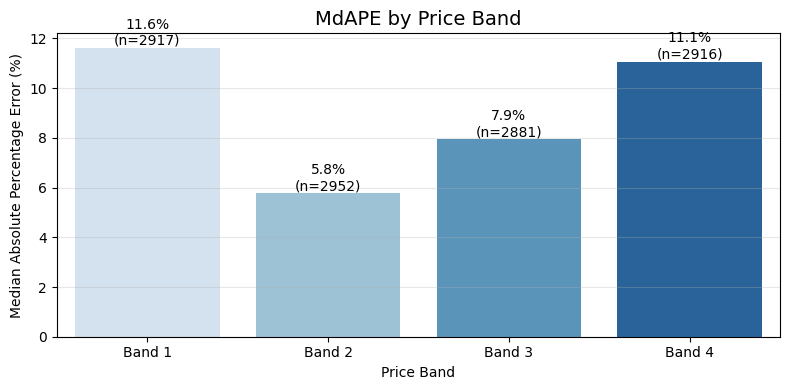

,Band,Min Price,Max Price,Count,MAE,MAPE (%),MdAPE (%),% Within 5%,% Within 10%
0,Band 1,195000.0,629990.0,2917,76773.908082,19.128527,11.625895,23.174494,43.949263
1,Band 2,630000.0,910000.0,2952,69768.471936,9.109378,5.763456,45.155827,70.257453
2,Band 3,911000.0,1470000.0,2881,124954.585657,10.693508,7.945702,33.425894,59.493232
3,Band 4,1471000.0,7175000.0,2916,364200.354895,13.985179,11.067946,23.182442,45.644719


In [38]:
price_band_results_xgb_app = evaluate_by_price_band(
    xgb_model_app,
    X_test_app,
    y_test_app,
    n_bands=4
)

price_band_results_xgb_app

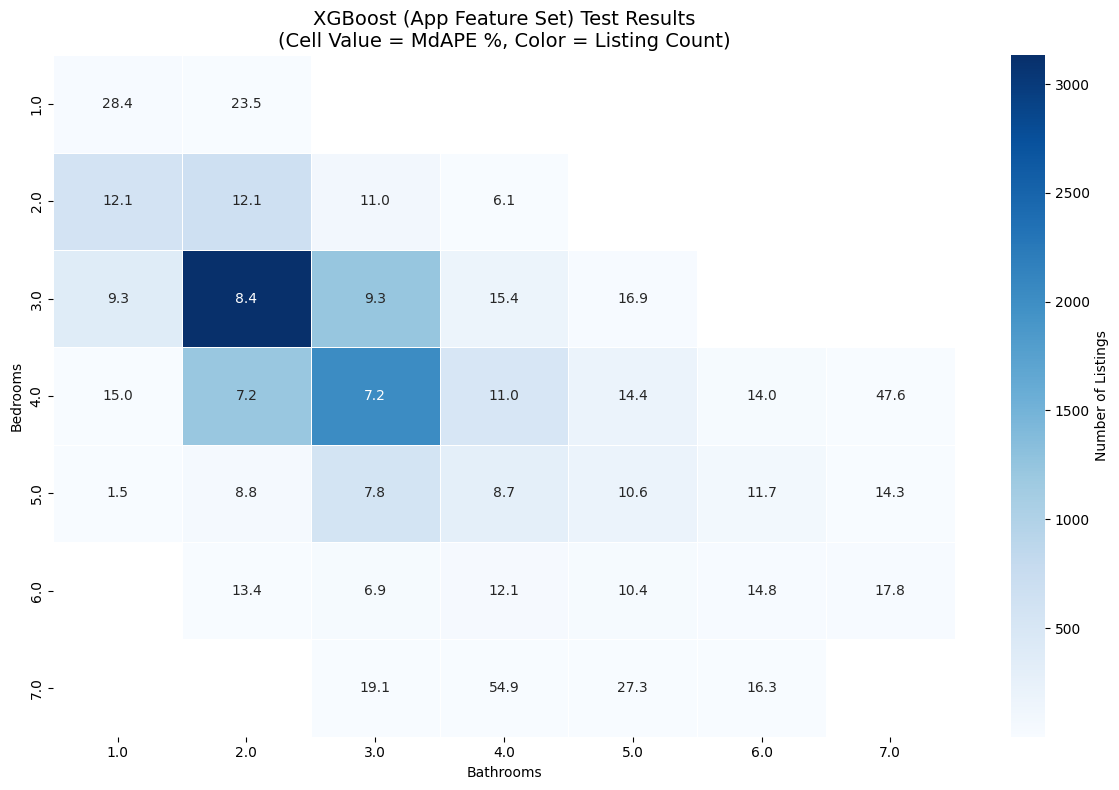

(Bathrooms        1.0        2.0        3.0        4.0        5.0        6.0  \
 Bedrooms                                                                      
 1.0        28.402883  23.504991        NaN        NaN        NaN        NaN   
 2.0        12.146619  12.130594  10.969080   6.137720        NaN        NaN   
 3.0         9.286923   8.402567   9.274085  15.398310  16.925271        NaN   
 4.0        15.008931   7.160259   7.234667  11.024788  14.449778  14.008190   
 5.0         1.533404   8.750196   7.772545   8.696056  10.646751  11.681632   
 6.0              NaN  13.401985   6.933358  12.110391  10.416574  14.804471   
 7.0              NaN        NaN  19.087908  54.937514  27.336587  16.261528   
 
 Bathrooms        7.0  
 Bedrooms              
 1.0              NaN  
 2.0              NaN  
 3.0              NaN  
 4.0        47.556304  
 5.0        14.278577  
 6.0        17.842421  
 7.0              NaN  ,
 Bathrooms    1.0     2.0     3.0    4.0    5.0   6.0   7.0
 

In [39]:
plot_mdape_bed_bath_matrix(
    xgb_model_app,
    X_test_app,
    y_test_app,
    title="XGBoost (App Feature Set) Test Results"
)

In [45]:
all_results = pd.concat([
    results_lr_app.assign(Model="Linear Regression"),
    results_dt_app.assign(Model="Decision Tree"),
    results_rf_app.assign(Model="Random Forest"),
    results_xgb_app.assign(Model="XGBoost")
])

display(all_results)

,Dataset,R-Squared,MAE,RMSE,MAPE (%),MdAPE (%),Model
0,Train,0.886408,161068.518183,293016.849701,13.851312,10.134863,Linear Regression
1,Test,0.896615,163610.151020,294737.081159,13.586926,10.075945,Linear Regression
0,Train,0.901259,148272.113003,273191.640390,12.153048,8.339637,Decision Tree
1,Test,0.885540,162656.097872,310122.849463,12.487682,8.409593,Decision Tree
0,Train,0.927452,132370.588916,234170.925187,11.136882,7.689639,Random Forest
1,Test,0.901991,151843.249812,286971.761374,11.800930,7.880279,Random Forest
0,Train,0.887099,154485.940125,292124.293445,13.520470,9.042467,XGBoost
1,Test,0.894401,158744.078106,297875.818425,13.224548,8.810279,XGBoost
